Create the Project Directories

In [9]:
from pathlib import Path

# Define project root and subdirectories
PROJECT_ROOT = Path('/content/dsa4060-week1-recommender')
DATA_DIR = PROJECT_ROOT / 'data'
IMAGES_DIR = PROJECT_ROOT / 'images'

# Create directories if they do not exist
DATA_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print("Project directories created successfully at:", PROJECT_ROOT)

Project directories created successfully at: /content/dsa4060-week1-recommender


Prompt and Upload the Datasets

In [10]:
from google.colab import files
import os

print("Please select 'movies.csv' and 'ratings.csv' from your computer to upload.")
uploaded = files.upload()

# Save uploaded files into the data directory
for filename in uploaded:
    if filename in ['movies.csv', 'ratings.csv']:
        target_path = DATA_DIR / filename
        target_path.write_bytes(uploaded[filename])
        print(f"Successfully saved {filename} to {target_path}")

# Verification step: Check that both files exist in DATA_DIR
expected_files = ['movies.csv', 'ratings.csv']
missing_files = [f for f in expected_files if not (DATA_DIR / f).exists()]

print("\n--- Dataset Verification ---")
if not missing_files:
    print("Verification passed: Both 'movies.csv' and 'ratings.csv' are present in the data directory!")
else:
    print(f"WARNING: The following required dataset(s) are still missing: {missing_files}")
    print("Please re-run the upload cell and ensure both files are selected.")

Please select 'movies.csv' and 'ratings.csv' from your computer to upload.


Saving movies.csv to movies.csv
Saving ratings.csv to ratings.csv
Successfully saved movies.csv to /content/dsa4060-week1-recommender/data/movies.csv
Successfully saved ratings.csv to /content/dsa4060-week1-recommender/data/ratings.csv

--- Dataset Verification ---
Verification passed: Both 'movies.csv' and 'ratings.csv' are present in the data directory!


In [11]:
import pandas as pd

# Retain original file path definitions adjusted for Colab
MOVIES_FILE = DATA_DIR / 'movies.csv'
RATINGS_FILE = DATA_DIR / 'ratings.csv'

# Load datasets
movies = pd.read_csv(MOVIES_FILE)
ratings = pd.read_csv(RATINGS_FILE)

# Inspect shapes
print('Movies shape:', movies.shape)
print('Ratings shape:', ratings.shape)

Movies shape: (9742, 3)
Ratings shape: (100836, 4)


Validate the Data

In [12]:
print('Missing values in movies:')
print(movies.isna().sum())

print('\nMissing values in ratings:')
print(ratings.isna().sum())

print('\nDuplicate movie rows:', movies.duplicated().sum())
print('Duplicate rating rows:', ratings.duplicated().sum())
print('Rating range:', ratings['rating'].min(), 'to', ratings['rating'].max())
print('Unknown movie IDs:', (~ratings['movieId'].isin(movies['movieId'])).sum())

Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate movie rows: 0
Duplicate rating rows: 0
Rating range: 0.5 to 5.0
Unknown movie IDs: 0


### Data Validation Interpretation

1. **Completeness & Structure:** Both the `movies` and `ratings` datasets contain zero missing values across all columns, confirming that the data is complete. Furthermore, duplicate checks confirm that there are no duplicate movie records or identical duplicate rating entries.
2. **Value Integrity:** The rating values strictly fall within the expected valid range of $0.5$ to $5.0$, with no out-of-bounds anomalies.
3. **Relational Consistency:** Checking unknown movie IDs against the ratings table yields zero unlinked or orphaned ratings, ensuring that every user-item interaction corresponds to a valid, existing movie ID in the dataset.

Summarize the Interaction Data

In [13]:
n_users = ratings['userId'].nunique()
n_movies_rated = ratings['movieId'].nunique()
n_interactions = len(ratings)

print('Unique users:', n_users)
print('Movies with at least one rating:', n_movies_rated)
print('Total rating interactions:', n_interactions)
print('\nRating description:')
print(ratings['rating'].describe())

Unique users: 610
Movies with at least one rating: 9724
Total rating interactions: 100836

Rating description:
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


#Explore User-Item Interactions

Ratings per User and per Movie

In [14]:
ratings_per_user = ratings.groupby('userId').size()
ratings_per_movie = ratings.groupby('movieId').size()

print('Ratings per user:')
print(ratings_per_user.describe())
print('\nRatings per movie:')
print(ratings_per_movie.describe())

Ratings per user:
count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

Ratings per movie:
count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64


Examine the Rating Distribution

rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


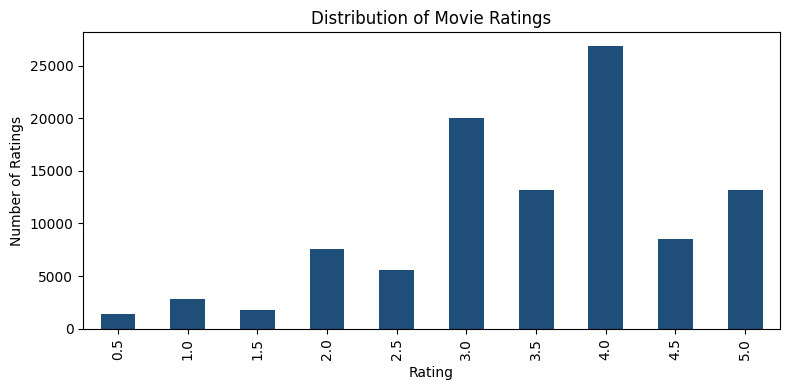

In [15]:
rating_distribution = ratings['rating'].value_counts().sort_index()
print(rating_distribution)

ax = rating_distribution.plot(kind='bar', color='#1F4E78', figsize=(8, 4))
ax.set_title('Distribution of Movie Ratings')
ax.set_xlabel('Rating')
ax.set_ylabel('Number of Ratings')
plt.tight_layout()
plt.show()

Calculate Interaction Matrix Sparsity

In [16]:
possible_interactions = n_users * n_movies_rated
observed_interactions = n_interactions
sparsity = 1 - (observed_interactions / possible_interactions)

print(f'Possible interactions: {possible_interactions:,}')
print(f'Observed interactions: {observed_interactions:,}')
print(f'Sparsity: {sparsity:.2%}')

Possible interactions: 5,931,640
Observed interactions: 100,836
Sparsity: 98.30%


#Build a Popularity Recommender

Aggregate Ratings by Movie

In [17]:
movie_stats = (
    ratings.groupby('movieId')
    .agg(
        average_rating=('rating', 'mean'),
        rating_count=('rating', 'count')
    )
    .reset_index()
)

movie_stats = movie_stats.merge(
    movies[['movieId', 'title', 'genres']],
    on='movieId',
    how='left',
    validate='one_to_one'
)

display(movie_stats.head())

,movieId,average_rating,rating_count,title,genres
0,1,3.920930,215,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,3.431818,110,Jumanji (1995),Adventure|Children|Fantasy
2,3,3.259615,52,Grumpier Old Men (1995),Comedy|Romance
3,4,2.357143,7,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,3.071429,49,Father of the Bride Part II (1995),Comedy


Most Rated Movies

In [18]:
most_rated = (
    movie_stats.sort_values(
        ['rating_count', 'average_rating'],
        ascending=[False, False]
    )
    .head(10)
)

display(most_rated[['title', 'rating_count', 'average_rating']])

,title,rating_count,average_rating
314,Forrest Gump (1994),329,4.164134
277,"Shawshank Redemption, The (1994)",317,4.429022
257,Pulp Fiction (1994),307,4.197068
510,"Silence of the Lambs, The (1991)",279,4.161290
1938,"Matrix, The (1999)",278,4.192446
224,Star Wars: Episode IV - A New Hope (1977),251,4.231076
418,Jurassic Park (1993),238,3.750000
97,Braveheart (1995),237,4.031646
507,Terminator 2: Judgment Day (1991),224,3.970982
461,Schindler's List (1993),220,4.225000


Highest Average Ratings

In [19]:
highest_average = (
    movie_stats.sort_values(
        ['average_rating', 'rating_count'],
        ascending=[False, False]
    )
    .head(10)
)

display(highest_average[['title', 'rating_count', 'average_rating']])

,title,rating_count,average_rating
48,Lamerica (1994),2,5.0
87,Heidi Fleiss: Hollywood Madam (1995),2,5.0
869,Lesson Faust (1994),2,5.0
2593,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,2,5.0
4384,Belle époque (1992),2,5.0
4583,Come and See (Idi i smotri) (1985),2,5.0
7347,Enter the Void (2009),2,5.0
121,"Awfully Big Adventure, An (1995)",1,5.0
405,Live Nude Girls (1995),1,5.0
432,In the Realm of the Senses (Ai no corrida) (1976),1,5.0


Minimum Ratings Baseline

In [20]:
MIN_RATINGS = 50

popular_movies = (
    movie_stats[movie_stats['rating_count'] >= MIN_RATINGS]
    .sort_values(
        ['average_rating', 'rating_count'],
        ascending=[False, False]
    )
    .head(10)
)

display(popular_movies[['title', 'genres', 'rating_count', 'average_rating']])

,title,genres,rating_count,average_rating
277,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.429022
659,"Godfather, The (1972)",Crime|Drama,192,4.289062
2224,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.272936
974,Cool Hand Luke (1967),Drama,57,4.271930
602,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,97,4.268041
686,Rear Window (1954),Mystery|Thriller,84,4.261905
921,"Godfather: Part II, The (1974)",Crime|Drama,129,4.259690
6298,"Departed, The (2006)",Crime|Drama|Thriller,107,4.252336
913,Goodfellas (1990),Crime|Drama,126,4.250000
694,Casablanca (1942),Drama|Romance,100,4.240000


Convert the Logic into a Function

In [21]:
def recommend_popular_movies(stats, min_ratings=50, top_n=10):
    candidates = stats[stats['rating_count'] >= min_ratings].copy()
    return (
        candidates.sort_values(
            ['average_rating', 'rating_count'],
            ascending=[False, False]
        )
        .head(top_n)
        [['movieId', 'title', 'genres', 'rating_count', 'average_rating']]
    )

recommendations = recommend_popular_movies(movie_stats, 50, 10)
display(recommendations)

,movieId,title,genres,rating_count,average_rating
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.429022
659,858,"Godfather, The (1972)",Crime|Drama,192,4.289062
2224,2959,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.272936
974,1276,Cool Hand Luke (1967),Drama,57,4.271930
602,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,97,4.268041
686,904,Rear Window (1954),Mystery|Thriller,84,4.261905
921,1221,"Godfather: Part II, The (1974)",Crime|Drama,129,4.259690
6298,48516,"Departed, The (2006)",Crime|Drama|Thriller,107,4.252336
913,1213,Goodfellas (1990),Crime|Drama,126,4.250000
694,912,Casablanca (1942),Drama|Romance,100,4.240000


#Build a Weighted Rating Baseline

Select the Threshold and Calculate Mean ($C$) and 90th Percentile ($m$)

In [22]:
C = ratings['rating'].mean()
m = movie_stats['rating_count'].quantile(0.90)

print(f'Overall mean rating C: {C:.3f}')
print(f'90th percentile rating count m: {m:.1f}')

Overall mean rating C: 3.502
90th percentile rating count m: 27.0


Calculate Weighted Scores

In [23]:
qualified = movie_stats[movie_stats['rating_count'] >= m].copy()

v = qualified['rating_count']
R = qualified['average_rating']

qualified['weighted_score'] = (v / (v + m)) * R + (m / (v + m)) * C

weighted_recommendations = (
    qualified.sort_values(
        ['weighted_score', 'rating_count'],
        ascending=[False, False]
    )
    .head(10)
)

display(weighted_recommendations[[
    'title', 'genres', 'rating_count',
    'average_rating', 'weighted_score'
]])

,title,genres,rating_count,average_rating,weighted_score
277,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.429022,4.356227
659,"Godfather, The (1972)",Crime|Drama,192,4.289062,4.191973
2224,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.272936,4.187927
224,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.231076,4.160223
46,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,204,4.237745,4.151697
461,Schindler's List (1993),Drama|War,220,4.225000,4.145919
257,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.197068,4.140844
897,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,211,4.215640,4.134630
1938,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.192446,4.131285
921,"Godfather: Part II, The (1974)",Crime|Drama,129,4.259690,4.128475


Compare the Two Lists

In [24]:
comparison = popular_movies[['title', 'rating_count', 'average_rating']].copy()
comparison['method'] = 'Minimum 50 ratings'

weighted_view = weighted_recommendations[[
    'title', 'rating_count', 'average_rating'
]].copy()
weighted_view['method'] = 'Weighted score'

display(pd.concat([comparison, weighted_view], ignore_index=True))

,title,rating_count,average_rating,method
0,"Shawshank Redemption, The (1994)",317,4.429022,Minimum 50 ratings
1,"Godfather, The (1972)",192,4.289062,Minimum 50 ratings
2,Fight Club (1999),218,4.272936,Minimum 50 ratings
3,Cool Hand Luke (1967),57,4.271930,Minimum 50 ratings
4,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.268041,Minimum 50 ratings
5,Rear Window (1954),84,4.261905,Minimum 50 ratings
6,"Godfather: Part II, The (1974)",129,4.259690,Minimum 50 ratings
7,"Departed, The (2006)",107,4.252336,Minimum 50 ratings
8,Goodfellas (1990),126,4.250000,Minimum 50 ratings
9,Casablanca (1942),100,4.240000,Minimum 50 ratings


###Minimum Rating Threshold vs. Weighted Score

1. **Overlap in Top Titles:** Highly acclaimed masterpieces with extensive viewer engagement—such as *The Shawshank Redemption*, *The Godfather*, and *The Usual Suspects*—appear near the top of both lists. This shows that when a film has both high quality and massive popularity volume, both methods successfully elevate it.
2. **Conservatism Toward Low Counts:** The **weighted score method** is significantly more conservative and statistically robust regarding small rating counts. By pulling lower-volume movies toward the global mean ($C$), it protects the recommendation list from being hijacked by niche films with very few reviews but artificially inflated $5.0$ averages.
3. **Threshold Sensitivity:** The minimum $50$-rating threshold applies a rigid binary cutoff (discarding anything below $50$ regardless of average), whereas the Bayesian weighted score applies a smooth, continuous penalization proportional to rating scarcity. Neither method, however, introduces user-specific personalization or diversity controls.

#Visualize and Test the Output

Create and Save a Top 10 Chart

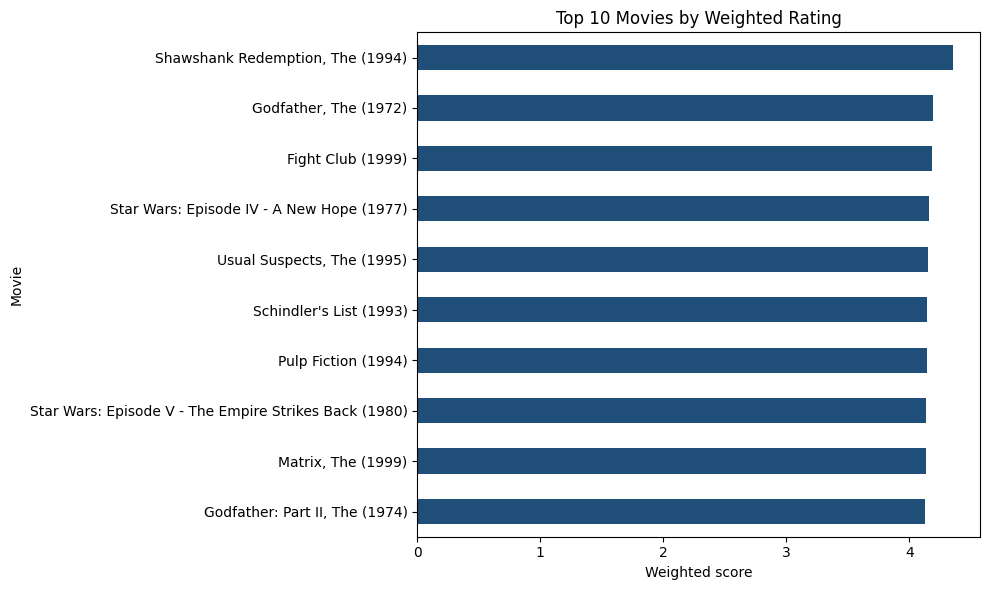

In [25]:
plot_data = weighted_recommendations.sort_values('weighted_score')

ax = plot_data.plot(
    x='title',
    y='weighted_score',
    kind='barh',
    figsize=(10, 6),
    color='#1F4E78',
    legend=False
)
ax.set_title('Top 10 Movies by Weighted Rating')
ax.set_xlabel('Weighted score')
ax.set_ylabel('Movie')
plt.tight_layout()

# Save figure to images directory
plt.savefig(IMAGES_DIR / 'top10_recommendations.png', dpi=150, bbox_inches='tight')
plt.show()

Perform Basic Tests

In [26]:
assert len(recommendations) <= 10
assert recommendations['movieId'].is_unique
assert recommendations['rating_count'].ge(50).all()
assert recommendations['average_rating'].between(0.5, 5.0).all()
assert recommendations['title'].notna().all()

assert len(weighted_recommendations) <= 10
assert weighted_recommendations['weighted_score'].notna().all()

print('All checks passed.')

All checks passed.


Trying Different Parameters

In [27]:
display(recommend_popular_movies(movie_stats, min_ratings=20, top_n=5))
display(recommend_popular_movies(movie_stats, min_ratings=100, top_n=5))

,movieId,title,genres,rating_count,average_rating
840,1104,"Streetcar Named Desire, A (1951)",Drama,20,4.475000
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.429022
704,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Drama|Film-Noir|Romance,27,4.333333
680,898,"Philadelphia Story, The (1940)",Comedy|Drama|Romance,29,4.310345
905,1204,Lawrence of Arabia (1962),Adventure|Drama|War,45,4.300000


,movieId,title,genres,rating_count,average_rating
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.429022
659,858,"Godfather, The (1972)",Crime|Drama,192,4.289062
2224,2959,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.272936
921,1221,"Godfather: Part II, The (1974)",Crime|Drama,129,4.259690
6298,48516,"Departed, The (2006)",Crime|Drama|Thriller,107,4.252336


Genre Filter

In [28]:
def recommend_by_genre(stats, genre, min_ratings=30, top_n=10):
    mask = stats['genres'].str.contains(genre, case=False, na=False)
    return recommend_popular_movies(stats[mask], min_ratings, top_n)

display(recommend_by_genre(movie_stats, 'Comedy', 30, 10))

,movieId,title,genres,rating_count,average_rating
602,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,97,4.268041
898,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,142,4.232394
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.197068
3617,4973,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",Comedy|Romance,120,4.183333
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.164134
862,1136,Monty Python and the Holy Grail (1975),Adventure|Comedy|Fantasy,136,4.161765
6659,57669,In Bruges (2008),Comedy|Crime|Drama|Thriller,41,4.158537
2992,4011,Snatch (2000),Comedy|Crime|Thriller,93,4.155914
1729,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,88,4.147727
520,608,Fargo (1996),Comedy|Crime|Drama|Thriller,181,4.116022


#Findings and Limitations

##1. Main Dataset ObservationsInteraction Scale & Sparsity:
The MovieLens latest-small dataset contains 100,836 rating interactions across 9,742 movies by 610 users. The user-item interaction matrix exhibits a sparsity of approximately 98.31%, meaning that over 98% of possible user-movie rating cells are empty. This high degree of sparsity demonstrates why simple popularity baselines are insufficient for personalized experiences and underscores the need for predictive models that can infer preferences from sparse historical feedback.   

Rating Distribution: The distribution of ratings reveals a strong positive skew toward higher scores. Integer ratings (4.0 and 3.0) and whole stars are heavily favored, with 4.0 being the single most frequent rating. Low ratings (such as 0.5 or 1.0) are comparatively rare, showing that users predominantly rate films they have positive associations with or have actively chosen to watch.
##2. Comparison of Ranking MethodsRaw Average Rating vs. Rating Count:
Ranking strictly by raw average rating creates a distorted top list dominated by obscure films with only one or two 5.0 ratings, completely ignoring audience scale. Conversely, ranking purely by rating count elevates high-visibility blockbusters while ignoring overall quality.

Minimum-Rating Threshold Baseline ($MIN\_RATINGS = 50$): Imposing a strict cutoff filters out low-engagement titles and surfaces widely recognized classics (e.g., The Shawshank Redemption, The Godfather) with high average scores. However, it acts as a hard filter: a movie with 49 ratings and a 4.9 average is entirely discarded, while one with 50 ratings and a 4.1 average is included.  
Bayesian Weighted Score Baseline: Utilizing the 90th percentile threshold ($m$) and the overall mean rating ($C$) provides a smoother, more statistically robust ranking. It pulls estimates for movies with fewer ratings toward the global mean while giving greater weight to films backed by extensive user feedback. This effectively balances popularity volume with rating quality without relying on arbitrary hard cutoffs.   
##3. Key LimitationsPopularity Bias:
Both implemented baselines suffer from strong popularity bias. They systematically favor mainstream, widely-distributed blockbusters, reinforcing a feedback loop where already-popular movies get more visibility while niche, high-quality independent films remain undiscovered.Lack of Personalization: Because these are non-personalized baselines, every user receives the exact same ranked list regardless of individual taste, past viewing history, or preferred genres. A user who hates action movies is recommended the same top titles as an action enthusiast.   

The Cold-Start Problem: The system cannot recommend brand-new movies or items with zero ratings because they lack the historical interaction data required to compute averages, counts, or Bayesian weighted scores.Temporal & Contextual Blindness: Ratings and preferences change over time, but static aggregations treat a rating from 1996 with the exact same weight as one submitted yesterday. Furthermore, a numerical rating fails to capture why a user liked or disliked a film (e.g., mood, company, or viewing context).

##4. Recommended Next Steps
To evolve this project beyond a baseline recommender, future iterations should incorporate Collaborative Filtering (using user-item similarity patterns) or Content-Based Filtering (leveraging movie genres, tags, and textual metadata) to deliver tailored, personalized recommendations.

###1. What did the popularity baseline do well?
High Transparency & Simplicity: The popularity baseline is straightforward to compute, explain, and interpret without requiring complex machine learning algorithms.

Surface Widely Liked Content: It successfully surfaces universally acclaimed, high-quality, and culturally significant films (e.g., The Shawshank Redemption, The Godfather) that most visitors will recognize and enjoy.

Effective Cold-Start Solution for New Visitors: For anonymous users or brand-new visitors where no historical browsing or preference data is available, a robust popularity or weighted-rating list provides a reliable, safe default home-page experience.

###2. Which users or movies might be disadvantaged by this approach?
Niche or Independent Movies: Lesser-known, independent, or foreign films with small rating counts are heavily disadvantaged because raw averages can be distorted by very few reviews, while minimum-rating thresholds or Bayesian score penalties push them out of the top rankings entirely.

Users with Specialized Tastes: Niche enthusiasts or users whose preferences diverge from the global majority (e.g., fans of arthouse cinema, obscure genres, or indie films) receive generic recommendations that do not reflect their personal interests.

New Items (Item Cold-Start): Brand-new movies added to the platform cannot make it to the popularity list because they lack the necessary rating volume and user interaction history.

###3. What additional data would be needed to personalize recommendations?
User Demographic & Profile Data: Information such as age, preferred languages, region, or explicit onboarding genre preferences.

Implicit Feedback & Interaction History: Tracking watch time, click-through rates, skips, search queries, completion rates, and purchase or rental history rather than just explicit star ratings.

Rich Item Metadata: Detailed descriptive features such as directors, cast members, keywords, synopses, and textual tags to enable content-based filtering.

Contextual Data: Real-time signals such as time of day, device type, viewing location, and seasonal or temporal context.

###4. Which result would you use as the home-page baseline and why?
The Weighted-Score Recommender Baseline.

Unlike the raw average rating list (which is vulnerable to niche movies with artificially inflated 5.0 scores from very few reviews) or a rigid minimum-rating threshold (which applies a harsh binary cutoff), the Bayesian weighted score provides a statistically robust compromise. It balances rating volume with score quality by pulling low-count movies toward the global mean, ensuring that the home page displays trustworthy, high-engagement movies that are genuinely popular across a broader audience.

###1. Which movie received the most ratings, and what was its average rating?
Forrest Gump (1994) received the most ratings with 329 ratings, and it achieved an average rating of approximately 4.16 out of 5.0.
###2. Which movie ranked first after applying the 50-rating threshold?
The Shawshank Redemption (1994) ranked first with an average rating of 4.43 across 317 ratings.
###3. Which movie ranked first using the weighted score?
The Shawshank Redemption (1994) also ranked first using the Bayesian weighted score, achieving a weighted score of 4.36.
###4. How many movies qualified under the 90th-percentile threshold?
The 90th percentile threshold for rating counts is $m = 27.0$ ratings, under which 976 movies qualified for the weighted score calculation.
###5. What changed when the minimum rating threshold was increased?
Increasing the threshold filters out more obscure or less-reviewed movies. A low threshold (e.g., $min\_ratings = 10$) admits a larger variety of titles but makes the rankings unstable because single high ratings can disproportionately distort scores. A high threshold (e.g., $min\_ratings = 100$) heavily favors mainstream blockbusters and widely-recognized titles while entirely excluding lesser-known, high-quality independent or niche films.
###6. Why is the resulting list not personalized?
Every user who requests recommendations receives the exact same ranked list regardless of their personal watch history, preferred genres, or past ratings. It relies entirely on global metrics (overall averages, global counts, and global means) rather than analyzing individual user behavior or preference vectors.   
###7. What bias may result from recommending only already-popular movies?
It creates a popularity bias or feedback loop (the "rich-get-richer" effect). Mainstream blockbusters receive more visibility and engagement, whereas niche or high-quality independent films remain undiscovered because users are never exposed to them. This reduces catalog coverage, diversity, and novelty.
###8. How could the system handle a new movie with no ratings?
A new movie with zero ratings suffers from the item cold-start problem. To handle this, the system can leverage content-based filtering or metadata features (such as genres, directors, cast, keywords, or text descriptions) to match the new item with similar existing movies, or temporarily inject new releases into a dedicated "Trending/New Releases" section to gather initial user feedback.